In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             matthews_corrcoef, make_scorer, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report, roc_auc_score,
                             roc_curve)
from sklearn.decomposition import PCA
from sklearn.base import clone

RANDOM_STATE = 42

In [2]:
df = pd.read_excel("D:\\ParkinsonProject\\data\\Parkinson.xlsx")
df.head()

,Source.Name,name,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
0,parkinsons.data,phon_R01_S01_1,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.00554,0.01109,...,0.06545,0.02211,21.033,1,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654
1,parkinsons.data,phon_R01_S01_2,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.00696,0.01394,...,0.09403,0.01929,19.085,1,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674
2,parkinsons.data,phon_R01_S01_3,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.00781,0.01633,...,0.08270,0.01309,20.651,1,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634
3,parkinsons.data,phon_R01_S01_4,116.676,137.871,111.366,0.00997,0.00009,0.00502,0.00698,0.01505,...,0.08771,0.01353,20.644,1,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975
4,parkinsons.data,phon_R01_S01_5,116.014,141.781,110.655,0.01284,0.00011,0.00655,0.00908,0.01966,...,0.10470,0.01767,19.649,1,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335


In [3]:
print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())
print("\nClass distribution:")
print(df['status'].value_counts())
print("\nDescriptive statistics:")
display(df.describe())

Shape: (195, 25)

Data types:
Source.Name          object
name                 object
MDVP:Fo(Hz)         float64
MDVP:Fhi(Hz)        float64
MDVP:Flo(Hz)        float64
MDVP:Jitter(%)      float64
MDVP:Jitter(Abs)    float64
MDVP:RAP            float64
MDVP:PPQ            float64
Jitter:DDP          float64
MDVP:Shimmer        float64
MDVP:Shimmer(dB)    float64
Shimmer:APQ3        float64
Shimmer:APQ5        float64
MDVP:APQ            float64
Shimmer:DDA         float64
NHR                 float64
HNR                 float64
status                int64
RPDE                float64
DFA                 float64
spread1             float64
spread2             float64
D2                  float64
PPE                 float64
dtype: object

Missing values:
Source.Name         0
name                0
MDVP:Fo(Hz)         0
MDVP:Fhi(Hz)        0
MDVP:Flo(Hz)        0
MDVP:Jitter(%)      0
MDVP:Jitter(Abs)    0
MDVP:RAP            0
MDVP:PPQ            0
Jitter:DDP          0
MDVP:Shimmer       

,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer(dB),...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
count,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,...,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000
mean,154.228641,197.104918,116.324631,0.006220,0.000044,0.003306,0.003446,0.009920,0.029709,0.282251,...,0.046993,0.024847,21.885974,0.753846,0.498536,0.718099,-5.684397,0.226510,2.381826,0.206552
std,41.390065,91.491548,43.521413,0.004848,0.000035,0.002968,0.002759,0.008903,0.018857,0.194877,...,0.030459,0.040418,4.425764,0.431878,0.103942,0.055336,1.090208,0.083406,0.382799,0.090119
min,88.333000,102.145000,65.476000,0.001680,0.000007,0.000680,0.000920,0.002040,0.009540,0.085000,...,0.013640,0.000650,8.441000,0.000000,0.256570,0.574282,-7.964984,0.006274,1.423287,0.044539
25%,117.572000,134.862500,84.291000,0.003460,0.000020,0.001660,0.001860,0.004985,0.016505,0.148500,...,0.024735,0.005925,19.198000,1.000000,0.421306,0.674758,-6.450096,0.174351,2.099125,0.137451
50%,148.790000,175.829000,104.315000,0.004940,0.000030,0.002500,0.002690,0.007490,0.022970,0.221000,...,0.038360,0.011660,22.085000,1.000000,0.495954,0.722254,-5.720868,0.218885,2.361532,0.194052
75%,182.769000,224.205500,140.018500,0.007365,0.000060,0.003835,0.003955,0.011505,0.037885,0.350000,...,0.060795,0.025640,25.075500,1.000000,0.587562,0.761881,-5.046192,0.279234,2.636456,0.252980
max,260.105000,592.030000,239.170000,0.033160,0.000260,0.021440,0.019580,0.064330,0.119080,1.302000,...,0.169420,0.314820,33.047000,1.000000,0.685151,0.825288,-2.434031,0.450493,3.671155,0.527367


In [4]:
df = df.drop(columns=['Source.Name', 'name'])
X = df.drop(columns=['status'])
y = df['status']

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (195, 22)
Target shape: (195,)


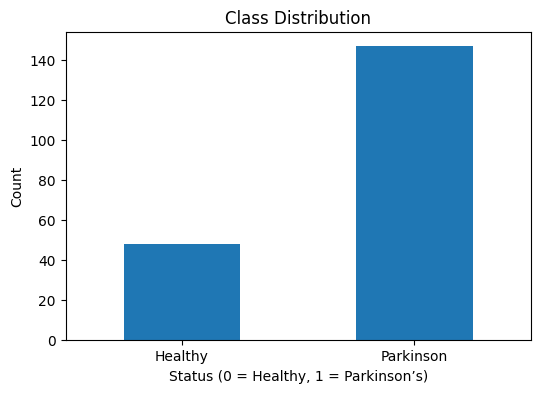

In [5]:
plt.figure(figsize=(6, 4))
y.value_counts().sort_index().plot(kind='bar')
plt.title('Class Distribution')
plt.xlabel('Status (0 = Healthy, 1 = Parkinson’s)')
plt.ylabel('Count')
plt.xticks([0, 1], ['Healthy', 'Parkinson'], rotation=0)
plt.show()

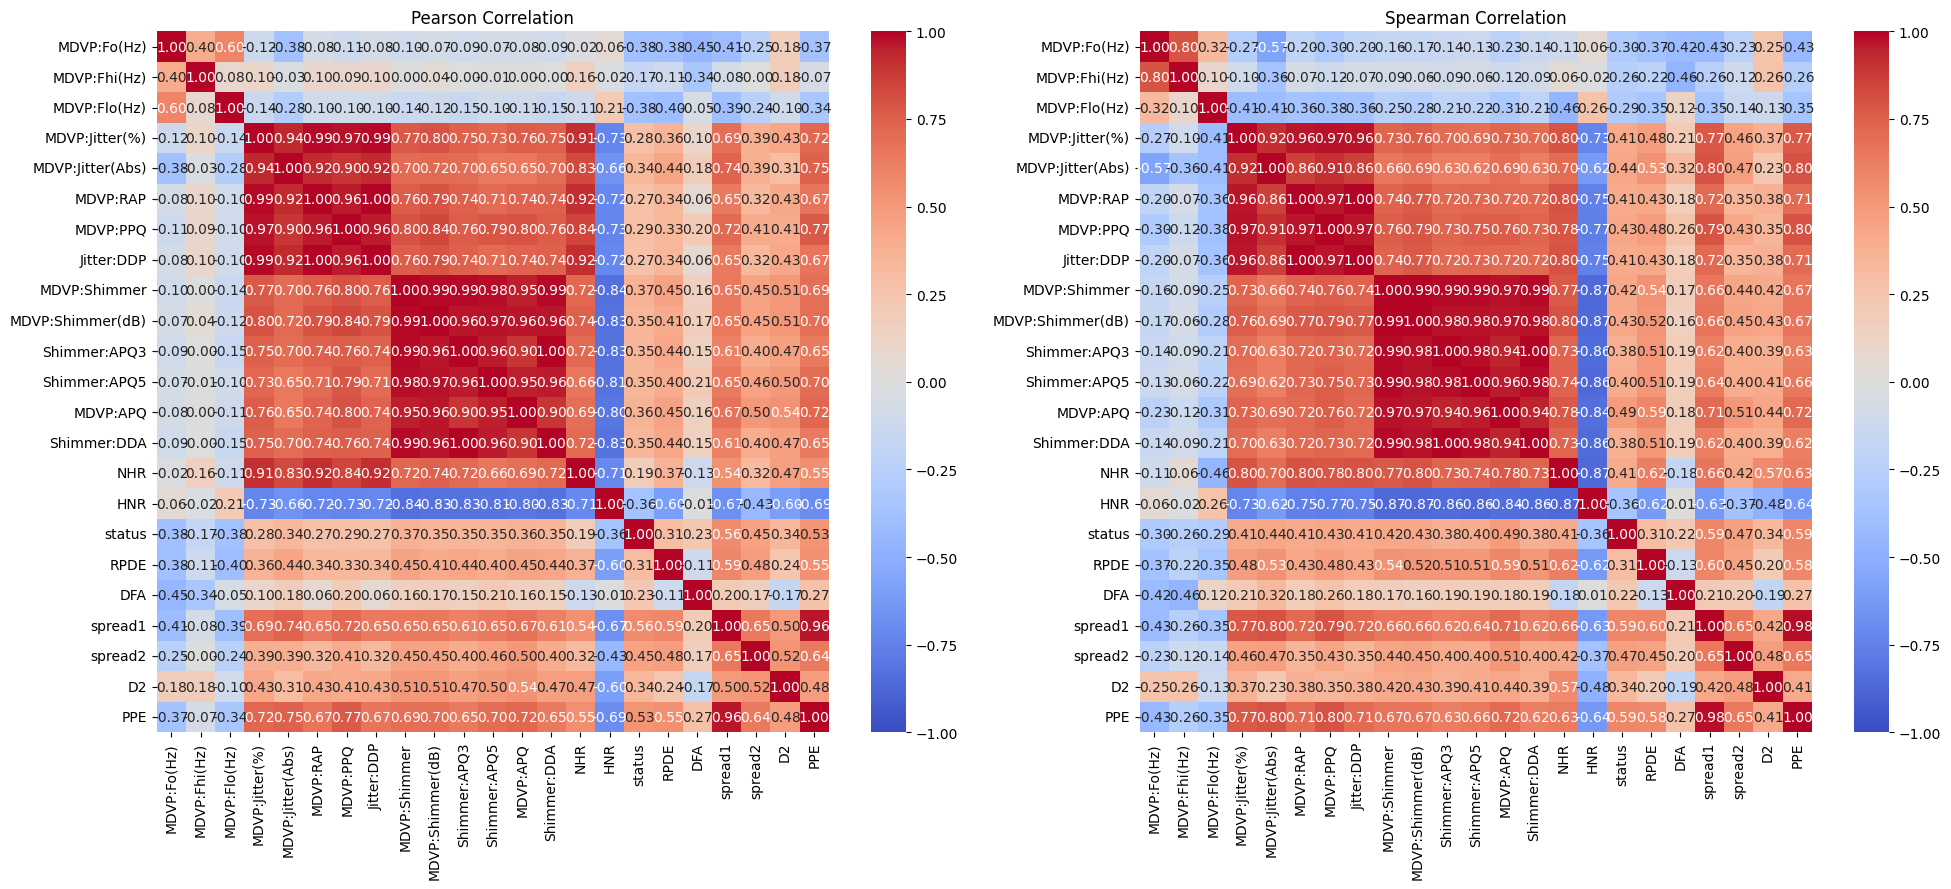

Pearson correlation with status:
status              1.000000
spread1             0.564838
PPE                 0.531039
spread2             0.454842
MDVP:Shimmer        0.367430
MDVP:APQ            0.364316
Shimmer:APQ5        0.351148
MDVP:Shimmer(dB)    0.350697
Shimmer:APQ3        0.347617
Shimmer:DDA         0.347608
D2                  0.340232
MDVP:Jitter(Abs)    0.338653
RPDE                0.308567
MDVP:PPQ            0.288698
MDVP:Jitter(%)      0.278220
MDVP:RAP            0.266668
Jitter:DDP          0.266646
DFA                 0.231739
NHR                 0.189429
MDVP:Fhi(Hz)       -0.166136
HNR                -0.361515
MDVP:Flo(Hz)       -0.380200
MDVP:Fo(Hz)        -0.383535
Name: status, dtype: float64

Spearman correlation with status:
status              1.000000
PPE                 0.592373
spread1             0.592373
MDVP:APQ            0.486314
spread2             0.468020
MDVP:Jitter(Abs)    0.435938
MDVP:PPQ            0.428585
MDVP:Shimmer(dB)    0.425419
MDVP

In [6]:
pearson_corr = df.corr(method='pearson')
spearman_corr = df.corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(20, 9))
sns.heatmap(pearson_corr, ax=axes[0], annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
axes[0].set_title('Pearson Correlation')
sns.heatmap(spearman_corr, ax=axes[1], annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
axes[1].set_title('Spearman Correlation')
plt.tight_layout()
plt.show()

print('Pearson correlation with status:')
print(pearson_corr['status'].sort_values(ascending=False))
print('\nSpearman correlation with status:')
print(spearman_corr['status'].sort_values(ascending=False))

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print('Training samples:', X_train.shape[0])
print('Test samples:', X_test.shape[0])
print('Training class distribution:')
print(y_train.value_counts())
print('Test class distribution:')
print(y_test.value_counts())

Training samples: 156
Test samples: 39
Training class distribution:
status
1    118
0     38
Name: count, dtype: int64
Test class distribution:
status
1    29
0    10
Name: count, dtype: int64


In [8]:
def evaluate_model(name, model, X_test, y_test):
    y_pred = model.predict(X_test)
    result = {
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1': f1_score(y_test, y_pred, zero_division=0),
        'MCC': matthews_corrcoef(y_test, y_pred)
    }
    if hasattr(model, 'predict_proba'):
        result['ROC-AUC'] = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
    elif hasattr(model, 'decision_function'):
        result['ROC-AUC'] = roc_auc_score(y_test, model.decision_function(X_test))
    else:
        result['ROC-AUC'] = np.nan
    return result

results = []

In [9]:
models = {
    'SVM': Pipeline([
        ('scaler', StandardScaler()),
        ('model', SVC(probability=True, random_state=RANDOM_STATE))
    ]),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    results.append(evaluate_model(name, model, X_test, y_test))

results_df = pd.DataFrame(results).sort_values('MCC', ascending=False)
results_df

,Model,Accuracy,Precision,Recall,F1,MCC,ROC-AUC
0,SVM,0.923077,0.906250,1.000000,0.950820,0.796477,0.955172
1,Random Forest,0.923077,0.933333,0.965517,0.949153,0.793363,0.962069


In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
mcc_scorer = make_scorer(matthews_corrcoef)

cv_rows = []
for name, model in models.items():
    search = GridSearchCV(model, param_grid={}, scoring=mcc_scorer, cv=cv, n_jobs=-1)
    search.fit(X_train, y_train)
    cv_rows.append({
        'Model': name,
        'CV MCC Mean': search.best_score_,
        'CV MCC Std': search.cv_results_['std_test_score'][0]
    })

cv_results_df = pd.DataFrame(cv_rows).sort_values('CV MCC Mean', ascending=False)
cv_results_df

,Model,CV MCC Mean,CV MCC Std
1,Random Forest,0.722052,0.104661
0,SVM,0.566166,0.145774


In [11]:
param_grids = {
    'Logistic Regression': {
        'model__C': [0.01, 0.1, 1, 10, 100]
    },
    'KNN': {
        'model__n_neighbors': [3, 5, 7, 9, 11],
        'model__weights': ['uniform', 'distance']
    },
    'SVM': {
        'model__kernel': ['rbf', 'linear'],
        'model__C': [0.1, 1, 10, 100],
        'model__gamma': ['scale', 'auto']
    },
    'Random Forest': {
        'n_estimators': [100, 200, 300],
        'max_depth': [3, 5, 7, 10, None],
        'min_samples_split': [2, 5, 10]
    },
    'MLP': {
        'model__hidden_layer_sizes': [(16,), (32,), (64,), (16, 16), (32, 32)],
        'model__activation': ['relu', 'tanh'],
        'model__alpha': [0.0001, 0.001, 0.01]
    }
}

tuned_models = {}
tuned_rows = []
for name, model in models.items():
    search = GridSearchCV(
        estimator=model,
        param_grid=param_grids[name],
        scoring=mcc_scorer,
        cv=cv,
        n_jobs=-1
    )
    search.fit(X_train, y_train)
    tuned_models[name] = search.best_estimator_
    row = evaluate_model(name, search.best_estimator_, X_test, y_test)
    row['Best CV MCC'] = search.best_score_
    row['Best Params'] = search.best_params_
    tuned_rows.append(row)

tuned_results_df = pd.DataFrame(tuned_rows).sort_values('MCC', ascending=False)
tuned_results_df[['Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'MCC', 'ROC-AUC', 'Best CV MCC', 'Best Params']]

,Model,Accuracy,Precision,Recall,F1,MCC,ROC-AUC,Best CV MCC,Best Params
1,Random Forest,0.923077,0.933333,0.965517,0.949153,0.793363,0.962069,0.722052,"{'max_depth': 5, 'min_samples_split': 2, 'n_es..."
0,SVM,0.897436,0.931034,0.931034,0.931034,0.731034,0.962069,0.718803,"{'model__C': 10, 'model__gamma': 'scale', 'mod..."


Best model: Random Forest
              precision    recall  f1-score   support

     Healthy       0.89      0.80      0.84        10
   Parkinson       0.93      0.97      0.95        29

    accuracy                           0.92        39
   macro avg       0.91      0.88      0.90        39
weighted avg       0.92      0.92      0.92        39



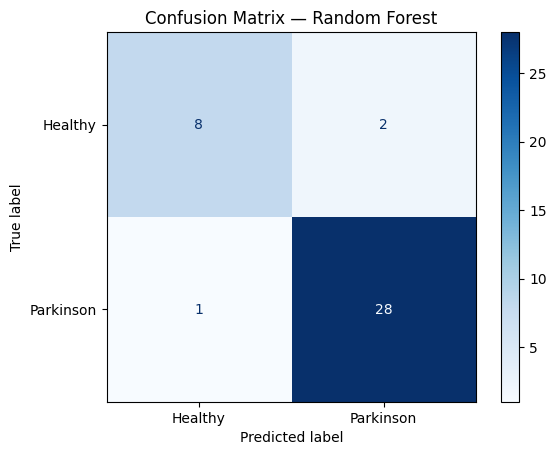

In [12]:
best_name = tuned_results_df.iloc[0]['Model']
best_model = tuned_models[best_name]

y_pred_best = best_model.predict(X_test)
print('Best model:', best_name)
print(classification_report(y_test, y_pred_best, target_names=['Healthy', 'Parkinson']))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_best, display_labels=['Healthy', 'Parkinson'], cmap='Blues'
)
plt.title(f'Confusion Matrix — {best_name}')
plt.show()

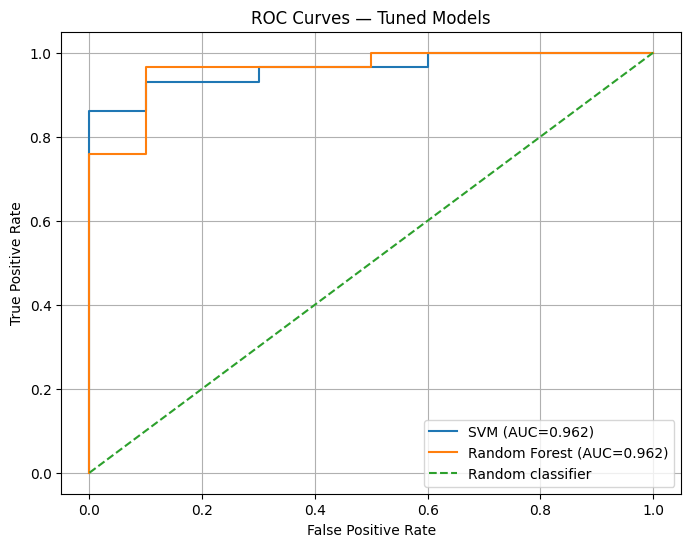

In [13]:
plt.figure(figsize=(8, 6))
for name, model in tuned_models.items():
    if hasattr(model, 'predict_proba'):
        scores = model.predict_proba(X_test)[:, 1]
    else:
        scores = model.decision_function(X_test)
    fpr, tpr, _ = roc_curve(y_test, scores)
    auc = roc_auc_score(y_test, scores)
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})')

plt.plot([0, 1], [0, 1], '--', label='Random classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves — Tuned Models')
plt.legend()
plt.grid(True)
plt.show()

,Feature,Importance
21,PPE,0.155235
18,spread1,0.112266
0,MDVP:Fo(Hz),0.060908
7,Jitter:DDP,0.059287
14,NHR,0.057286
2,MDVP:Flo(Hz),0.052098
5,MDVP:RAP,0.048522
1,MDVP:Fhi(Hz),0.046748
19,spread2,0.040211
11,Shimmer:APQ5,0.039686


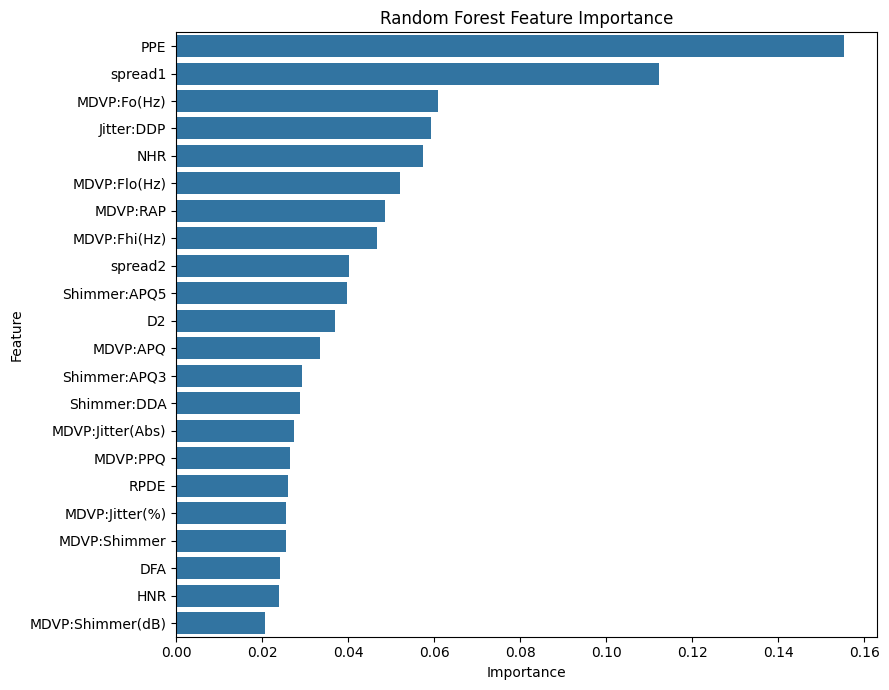

In [14]:
rf_model = tuned_models['Random Forest']
importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

display(importance_df)

plt.figure(figsize=(9, 7))
sns.barplot(data=importance_df, x='Importance', y='Feature')
plt.title('Random Forest Feature Importance')
plt.tight_layout()
plt.show()

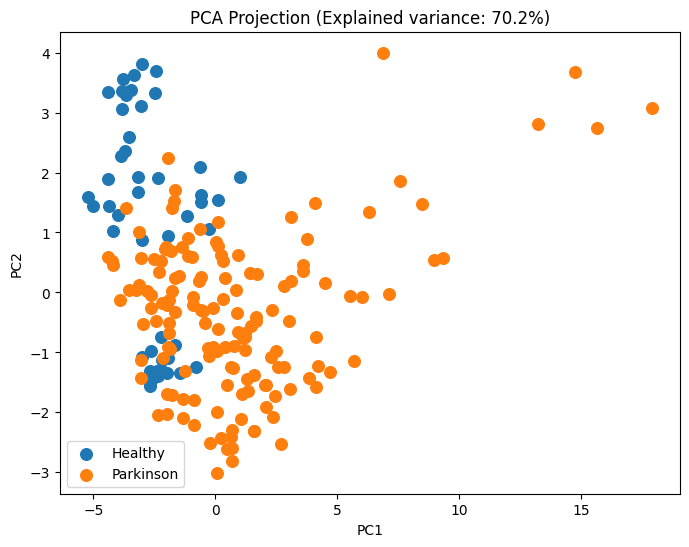

Explained variance ratio: [0.58900504 0.1129943 ]


In [15]:
X_scaled_for_pca = StandardScaler().fit_transform(X)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled_for_pca)

pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
pca_df['status'] = y.to_numpy()

plt.figure(figsize=(8, 6))
for label, group in pca_df.groupby('status'):
    plt.scatter(group['PC1'], group['PC2'], label='Parkinson' if label == 1 else 'Healthy', s=70)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title(f'PCA Projection (Explained variance: {pca.explained_variance_ratio_.sum():.1%})')
plt.legend()
plt.show()

print('Explained variance ratio:', pca.explained_variance_ratio_)